In [1]:

import pandas as pd

import matplotlib.pyplot as plt

import seaborn as sns

from sklearn. neighbors import KNeighborsClassifier

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler

from sklearn.metrics import accuracy_score

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score , mean_absolute_error

In [3]:
import pandas as pd

df = pd.read_csv(
    r"D:\AI-ML_class\hello_spam\spam.csv",
    encoding="latin-1"
)

In [4]:
df.columns

Index(['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], dtype='str')

In [5]:
df.drop(columns=["Unnamed: 2","Unnamed: 3","Unnamed: 4"],inplace=True)

In [6]:
df.rename(columns={'v1':'target','v2':'text'},inplace=True)

In [7]:
df

,target,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will Ì_ b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [8]:
df['text'][2]

"Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's"

In [9]:
df.duplicated().sum()

np.int64(403)

In [10]:
df.drop_duplicates(keep="first",inplace=True)

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.shape

(5169, 2)

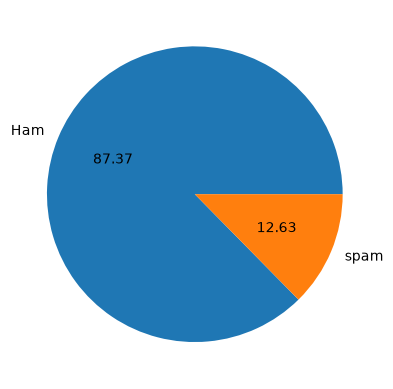

In [13]:
df["target"].value_counts().plot(kind="pie" , labels=["Ham","spam"],autopct="%0.2f");

In [14]:
! pip install nltk

In [15]:
import nltk
nltk.download('punkt')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Aman\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [16]:
df["num_char"]= df["text"].apply(len)

In [17]:
nltk.download("punkt_tab")


[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Aman\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [18]:
df

,target,text,num_char
0,ham,"Go until jurong point, crazy.. Available only ...",111
1,ham,Ok lar... Joking wif u oni...,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,ham,U dun say so early hor... U c already then say...,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",61
...,...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...,161
5568,ham,Will Ì_ b going to esplanade fr home?,37
5569,ham,"Pity, * was in mood for that. So...any other s...",57
5570,ham,The guy did some bitching but I acted like i'd...,125


In [19]:
df["num_words"] = df["text"].apply(lambda x:len(nltk.word_tokenize(x)))

df["num_sent"] = df["text"].apply(lambda x:len(nltk.sent_tokenize(x)))

In [20]:
df

,target,text,num_char,num_words,num_sent
0,ham,"Go until jurong point, crazy.. Available only ...",111,24,2
1,ham,Ok lar... Joking wif u oni...,29,8,2
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2
3,ham,U dun say so early hor... U c already then say...,49,13,1
4,ham,"Nah I don't think he goes to usf, he lives aro...",61,15,1
...,...,...,...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...,161,35,4
5568,ham,Will Ì_ b going to esplanade fr home?,37,9,1
5569,ham,"Pity, * was in mood for that. So...any other s...",57,15,2
5570,ham,The guy did some bitching but I acted like i'd...,125,27,1


In [21]:
nltk.download("stopwords")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Aman\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [22]:

from nltk.corpus import stopwords
import string
from nltk.stem.porter import PorterStemmer
ps = PorterStemmer()

In [23]:
def transform_text(text):
  text = text.lower()
  text = nltk.word_tokenize(text)
  y = []
  for i in text:
    if i.isalnum():
      y.append(i)
  text = y[:]
  y.clear()
  for i in text:
    if i not in stopwords.words('english') and i not in string.punctuation:
      y.append(i)
  t=y[:]
  y.clear()
  for i in t:
    y.append(ps.stem(i))
  return " ".join(y)

In [24]:
transform_text("did you like presentatin , @+ of machin  learning ?? ")

'like presentatin machin learn'

In [25]:
df["new_col"] = df["text"].apply(transform_text)

In [26]:
df

,target,text,num_char,num_words,num_sent,new_col
0,ham,"Go until jurong point, crazy.. Available only ...",111,24,2,go jurong point crazi avail bugi n great world...
1,ham,Ok lar... Joking wif u oni...,29,8,2,ok lar joke wif u oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entri 2 wkli comp win fa cup final tkt 21...
3,ham,U dun say so early hor... U c already then say...,49,13,1,u dun say earli hor u c alreadi say
4,ham,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah think goe usf live around though
...,...,...,...,...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...,161,35,4,2nd time tri 2 contact u pound prize 2 claim e...
5568,ham,Will Ì_ b going to esplanade fr home?,37,9,1,b go esplanad fr home
5569,ham,"Pity, * was in mood for that. So...any other s...",57,15,2,piti mood suggest
5570,ham,The guy did some bitching but I acted like i'd...,125,27,1,guy bitch act like interest buy someth els nex...


In [27]:
# ! pip install wordcloud
%pip install wordcloud
from wordcloud import WordCloud

Note: you may need to restart the kernel to use updated packages.


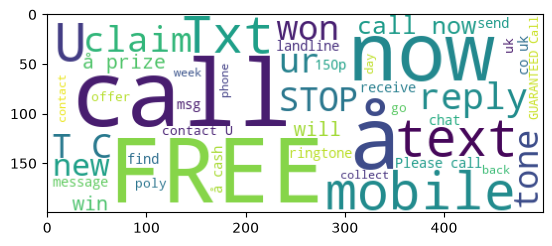

In [28]:
wc = WordCloud(width = 500, height=200,min_font_size= 10, background_color="white")
spam_word_cloud = wc.generate(df[df["target"]=="spam"]["text"].str.cat(sep = ""))
plt.imshow(spam_word_cloud);

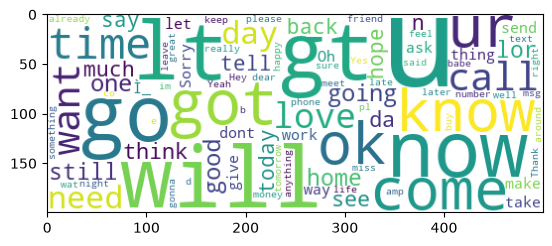

In [29]:
wc = WordCloud(width = 500, height=200,min_font_size= 10, background_color="white")
ham_word_cloud = wc.generate(df[df["target"]=="ham"]["text"].str.cat(sep = ""))
plt.imshow(ham_word_cloud);

In [30]:
y = df["target"]  # Change to the exact column name printed

In [31]:
print(df.columns)

Index(['target', 'text', 'num_char', 'num_words', 'num_sent', 'new_col'], dtype='str')


In [32]:
# Features and target
X_text = df["new_col"].fillna("").astype(str)
y = df["target"]

In [33]:
from pathlib import Path

In [34]:
import streamlit as st
import pickle
from pathlib import Path  # <--- Ye line add karein

# Saved files ko load karein
base_dir = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
cv_path = base_dir / "cv.pkl"

# ... baki ka code ...

In [36]:
import streamlit as st
import pickle
import string
import nltk
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer

# NLTK data download karna zaroori hai
nltk.download('punkt')
nltk.download('stopwords')

ps = PorterStemmer()

# Text preprocessing function jo aapne notebook mein banaya tha
def transform_text(text):
    text = text.lower()
    text = nltk.word_tokenize(text)
    y = []
    for i in text:
        if i.isalnum():
            y.append(i)
    text = y[:]
    y.clear()
    for i in text:
        if i not in stopwords.words('english') and i not in string.punctuation:
            y.append(i)
    t = y[:]
    y.clear()
    for i in t:
        y.append(ps.stem(i))
    return " ".join(y)

# Saved models ko load karein
try:
    cv = pickle.load(open('cv.pkl', 'rb'))
    tfidf = pickle.load(open('tfidf.pkl', 'rb'))
    model = pickle.load(open('model.pkl', 'rb'))
except (FileNotFoundError, pickle.UnpicklingError, EOFError) as e:
    st.error(
        "A model file is missing or corrupted. Regenerate cv.pkl, "
        "tfidf.pkl, and model.pkl, then try again."
    )
    st.stop()
    st.error("Model files (cv.pkl, tfidf.pkl, model.pkl) nahi mili. Kripya pehle notebook se inhe save karein.")
    st.stop()

# Streamlit App ka UI
st.title("SMS/Email Spam Classifier 📧")
st.write("Aapne jo ML model VS Code mein train kiya hai, ye uska frontend hai.")

# User se input lene ke liye text area
input_sms = st.text_area("Yahan apna message type karein:")

if st.button('Predict'):
    if input_sms.strip() == "":
        st.warning("Kripya koi message daalein!")
    else:
        # 1. Text ko Preprocess karein
        transformed_sms = transform_text(input_sms)
        
        # 2. Text ko Vectorize karein
        vector_input = cv.transform([transformed_sms])
        tfidf_input = tfidf.transform(vector_input)
        
        # 3. Model se Predict karein
        result = model.predict(tfidf_input)[0]
        
        # 4. Result display karein
        if result == 'spam':
            st.error("🚨 Ye ek SPAM message hai!")
        else:
            st.success("✅ Ye ek HAM (safe) message hai!")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Aman\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Aman\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
2026-10-16 14:42:48.069 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-16 14:42:48.532 
  command:

    streamlit run d:\New folder\New folder\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-10-16 14:42:48.534 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-16 14:42:48.537 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-16 14:42:48.538 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in 

In [ ]:
if st.button('Predict'):
    if input_sms.strip() == "":
        st.warning("Kripya koi message daalein!")
    else:
        # Text preprocess aur vectorize karein
        transformed_sms = transform_text(input_sms)
        vector_input = cv.transform([transformed_sms])
        tfidf_input = tfidf.transform(vector_input)
        
        # Model se predict karein
        result = model.predict(tfidf_input)[0]
        
        # Output dikhayein
        if result == 'spam':
            st.error("🚨 Ye ek SPAM message hai!")
        else:
            st.success("✅ Ye ek HAM (safe) message hai!")

2026-10-16 10:22:41.856 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-16 10:22:41.860 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-16 10:22:41.864 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-16 10:22:41.865 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-16 10:22:41.867 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-16 10:22:41.868 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
